In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
players = pd.read_csv("players.csv")
appearances = pd.read_csv("appearances.csv")
clubs = pd.read_csv("clubs.csv")
competitions = pd.read_csv("competitions.csv") 

In [3]:
players.shape

(50149, 26)

In [4]:
appearances.shape

(1894350, 13)

In [5]:
clubs.shape

(796, 17)

In [6]:
competitions.shape

(65, 11)

In [7]:
players.columns

Index(['player_id', 'first_name', 'last_name', 'name', 'last_season',
       'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name',
       'image_url', 'international_caps', 'international_goals',
       'current_national_team_id', 'url',
       'current_club_domestic_competition_id', 'current_club_name',
       'market_value_in_eur', 'highest_market_value_in_eur'],
      dtype='object')

In [8]:
appearances.columns

Index(['appearance_id', 'game_id', 'player_id', 'player_club_id',
       'player_current_club_id', 'date', 'player_name', 'competition_id',
       'yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played'],
      dtype='object')

In [9]:
clubs.columns

Index(['club_id', 'club_code', 'name', 'domestic_competition_id',
       'total_market_value', 'squad_size', 'average_age', 'foreigners_number',
       'foreigners_percentage', 'national_team_players', 'stadium_name',
       'stadium_seats', 'net_transfer_record', 'coach_name', 'last_season',
       'filename', 'url'],
      dtype='object')

In [10]:
competitions.columns

Index(['competition_id', 'competition_code', 'name', 'sub_type', 'type',
       'country_id', 'country_name', 'domestic_league_code', 'confederation',
       'total_clubs', 'url'],
      dtype='object')

In [11]:
players.columns

Index(['player_id', 'first_name', 'last_name', 'name', 'last_season',
       'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name',
       'image_url', 'international_caps', 'international_goals',
       'current_national_team_id', 'url',
       'current_club_domestic_competition_id', 'current_club_name',
       'market_value_in_eur', 'highest_market_value_in_eur'],
      dtype='object')

In [12]:
players.isnull().sum()

player_id                                   0
first_name                               3164
last_name                                   0
name                                        0
last_season                                 0
current_club_id                             0
player_code                                 0
country_of_birth                         5885
city_of_birth                            5608
country_of_citizenship                    269
date_of_birth                              49
sub_position                              586
position                                    0
foot                                     5893
height_in_cm                             4365
contract_expiration_date                18569
agent_name                              23296
image_url                                   0
international_caps                      30793
international_goals                     30793
current_national_team_id                46889
url                               

### Tablolar Arası Bağlantılar

| Tablolar | Sol Kolon | Sağ Kolon |
|---|---|---|
| players ↔ appearances | `player_id` | `player_id` |
| players ↔ clubs | `current_club_id` | `club_id` |
| appearances ↔ competitions | `competition_id` | `competition_id` |
| players ↔ competitions | `current_club_domestic_competition_id` | `competition_id` |

In [13]:
competitions["country_name"].unique()

array(['Austria', nan, 'Argentina', 'Australia', 'Belgium', 'Brazil',
       'Switzerland', 'Spain', 'Italy', 'Germany', 'Denmark', 'England',
       'France', 'Greece', 'Japan', 'Croatia', 'Mexico', 'United States',
       'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania',
       'Korea, South', 'Russia', 'Saudi Arabia', 'Scotland', 'Sweden',
       'Serbia', 'Türkiye', 'Czech Republic', 'Ukraine'], dtype=object)

In [14]:
competitions["country_name"] == "Türkiye"

0     False
1     False
2     False
3     False
4     False
      ...  
60    False
61    False
62    False
63    False
64    False
Name: country_name, Length: 65, dtype: bool

In [15]:
competitions[competitions["country_name"] == "Türkiye"]

,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code,confederation,total_clubs,url
59,TR1,super-lig,super-lig,first_tier,domestic_league,174,Türkiye,TR1,europa,18.0,https://www.transfermarkt.co.uk/super-lig/star...


In [16]:
clubs[clubs["domestic_competition_id"] == "TR1"]

,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,filename,url
22,10484,kasimpasa,Kasimpasa,TR1,NaN,37,24.6,15,40.5,5,Recep Tayyip Erdoğan Stadyumu,13797,€-3.70m,Shota Arveladze,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/kasimpasa/star...
66,11282,alanyaspor,Alanyaspor,TR1,NaN,28,25.9,13,46.4,6,Alanya Oba Stadyumu,9727,€-1.20m,João Pereira,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/alanyaspor/sta...
69,114,besiktas-istanbul,Beşiktaş Jimnastik Kulübü,TR1,NaN,28,26.2,14,50.0,10,Beşiktaş Park,42684,€-27.96m,NaN,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/besiktas-istan...
79,11688,giresunspor,Giresunspor,TR1,NaN,17,22.5,1,5.9,1,Çotanak Spor Kompleksi,21500,+-0,NaN,2022,../data/raw/transfermarkt-scraper/2022/clubs.j...,https://www.transfermarkt.co.uk/giresunspor/st...
88,120,kocaelispor,Kocaelispor,TR1,NaN,28,25.8,13,46.4,4,Turka Araç Muayene Kocaeli Stadyumu,34829,€-700k,Selçuk İnan,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/kocaelispor/st...
106,126,caykur-rizespor,Caykur Rizespor,TR1,NaN,30,25.4,16,53.3,6,Çaykur Didi,14879,€-2.50m,İlhan Palut,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/caykur-rizespo...
129,141,galatasaray-istanbul,Galatasaray,TR1,NaN,33,25.7,13,39.4,16,Ali Sami Yen Spor Kompleksi RAMS Park,53978,+€5.00m,Okan Buruk,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/galatasaray-is...
151,1467,goztepe,Göztepe,TR1,NaN,28,24.2,17,60.7,4,Gürsel Aksel Stadyumu,23376,€-2.20m,Stanimir Stoilov,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/goztepe/starts...
158,1506,kardemir-karabukspor,Kardemir Karabükspor,TR1,NaN,0,NaN,0,NaN,0,Dr. Necmettin Şeyhoğlu,12400,+-0,NaN,2017,../data/raw/transfermarkt-scraper/2017/clubs.j...,https://www.transfermarkt.co.uk/kardemir-karab...
160,152,samsunspor,Samsunspor,TR1,NaN,38,24.0,17,44.7,3,Samsun Yeni 19 Mayıs,34303,+-0,Thomas Reis,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/samsunspor/sta...


In [17]:
players["last_season"].value_counts().sort_index()

last_season
2012     1658
2013     2061
2014     1660
2015     1651
2016     1831
2017     1661
2018     2065
2019     1566
2020     1843
2021     1817
2022     1877
2023     2092
2024     6075
2025    22292
Name: count, dtype: int64

In [18]:
df = players[players["market_value_in_eur"].notnull()]
print(df.shape)

(41528, 26)


In [19]:
df = df[df["last_season"] == 2025]
print(df.shape)

(18404, 26)


In [20]:
df = df[df["current_club_domestic_competition_id"] == "TR1"]
print(df.shape)

(546, 26)


### data filtering

the dataset was narrowed from **50,149** players to **41,528** after removing players without a market value (the target variable), to **18,404** by keeping only players active in the 2025-26 season (`last_season == 2025`), and finally to **546** by keeping only players whose current club competes in the Turkish Süper Lig (`TR1`).

In [21]:
df["current_club_name"].value_counts().sort_index()

current_club_name
Alanyaspor                    29
Antalyaspor                   29
Basaksehir FK                 27
Beşiktaş Jimnastik Kulübü     37
Bodrum FK                      2
Caykur Rizespor               28
Erzurumspor FK                 1
Eyüpspor                      34
Fatih Karagümrük              29
Fenerbahce                    25
Galatasaray                   26
Gaziantep FK                  34
Gençlerbirliği Spor Kulübü    30
Göztepe                       29
Istanbulspor                   1
Kasimpasa                     37
Kayserispor                   32
Kocaelispor                   30
Konyaspor                     28
Samsunspor                    26
Sivasspor                      2
Trabzonspor                   30
Name: count, dtype: int64

In [22]:
df.isnull().sum() / len(df)

player_id                               0.000000
first_name                              0.051282
last_name                               0.000000
name                                    0.000000
last_season                             0.000000
current_club_id                         0.000000
player_code                             0.000000
country_of_birth                        0.018315
city_of_birth                           0.018315
country_of_citizenship                  0.000000
date_of_birth                           0.000000
sub_position                            0.000000
position                                0.000000
foot                                    0.005495
height_in_cm                            0.029304
contract_expiration_date                0.155678
agent_name                              0.289377
image_url                               0.000000
international_caps                      0.181319
international_goals                     0.181319
current_national_tea

In [23]:
superlig_clubs = clubs[
    (clubs["domestic_competition_id"] == "TR1") &
    (clubs["last_season"] == 2025)
]["club_id"]

In [24]:
print(len(superlig_clubs))

18


In [25]:
df = df[df["current_club_id"].isin(superlig_clubs)]
print(df.shape)

(540, 26)


In [26]:
df[df["contract_expiration_date"].isnull()][["name", "current_club_name", "position", "market_value_in_eur"]]


,name,current_club_name,position,market_value_in_eur
915,Lionel Carole,Kayserispor,Defender,200000.0
4022,Cenk Tosun,Kasimpasa,Attack,300000.0
4394,Efecan Karaca,Alanyaspor,Attack,100000.0
4561,Güray Vural,Antalyaspor,Defender,225000.0
5235,Gökhan Değirmenci,Kocaelispor,Goalkeeper,50000.0
...,...,...,...,...
46559,Umut İslamoğlu,Gençlerbirliği Spor Kulübü,Defender,50000.0
46890,Furkan Ulupınar,Kasimpasa,Defender,10000.0
47446,Yakub İlçin,Antalyaspor,Midfield,300000.0
47929,Berkay Topdemir,Antalyaspor,Attack,50000.0


In [27]:
df = df.drop(columns = ["first_name", "city_of_birth", "country_of_birth", "agent_name" , "current_national_team_id" , "highest_market_value_in_eur", "image_url", "url", "player_code"])  

In [28]:
print(df.shape)

(540, 17)


In [29]:
df["height_in_cm"] = df["height_in_cm"].fillna(df["height_in_cm"].median())

In [30]:
df["foot"] = df["foot"].fillna(df["foot"].mode()[0])

In [31]:
df[["height_in_cm", "foot"]].isnull().sum()

height_in_cm    0
foot            0
dtype: int64

In [32]:
df["contract_missing"] = df["contract_expiration_date"].isnull().astype(int)

In [33]:
df.columns

Index(['player_id', 'last_name', 'name', 'last_season', 'current_club_id',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'contract_expiration_date',
       'international_caps', 'international_goals',
       'current_club_domestic_competition_id', 'current_club_name',
       'market_value_in_eur', 'contract_missing'],
      dtype='object')

In [34]:
df["contract_missing"].value_counts()

contract_missing
0    455
1     85
Name: count, dtype: int64

In [35]:
appearances.columns
appearances.head()

,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,2234418_73333,2234418,73333,1274,76,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90


In [36]:
appearances["date"] = pd.to_datetime(appearances["date"])
app_recent = appearances[appearances["date"] >= "2024-07-01"]

In [37]:
player_stats = app_recent.groupby("player_id").agg(
    games=("game_id", "count"),
    minutes=("minutes_played", "sum"),
    goals=("goals", "sum"),
    assists=("assists", "sum"),
    yellow_cards=("yellow_cards","sum")
).reset_index()


In [38]:
player_stats.shape
player_stats.head()

,player_id,games,minutes,goals,assists,yellow_cards
0,3333,26,1119,1,1,3
1,5336,23,1211,0,0,4
2,7161,45,1939,6,5,4
3,7825,13,1125,0,0,0
4,8198,3,270,2,0,0


In [39]:
df = df.merge(player_stats, on="player_id",how="left")

In [40]:
df.shape
df[["games", "minutes", "goals"]].isnull().sum()

games      26
minutes    26
goals      26
dtype: int64

In [41]:
stat_cols = ["games", "minutes", "goals", "assists", "yellow_cards"]
df[stat_cols] = df[stat_cols].fillna(0)

In [42]:
print(df.shape)
df[stat_cols].isnull().sum()

(540, 23)


games           0
minutes         0
goals           0
assists         0
yellow_cards    0
dtype: int64

In [43]:
df.columns

Index(['player_id', 'last_name', 'name', 'last_season', 'current_club_id',
       'country_of_citizenship', 'date_of_birth', 'sub_position', 'position',
       'foot', 'height_in_cm', 'contract_expiration_date',
       'international_caps', 'international_goals',
       'current_club_domestic_competition_id', 'current_club_name',
       'market_value_in_eur', 'contract_missing', 'games', 'minutes', 'goals',
       'assists', 'yellow_cards'],
      dtype='object')

In [44]:
df.to_csv("superlig_players_clean.csv", index=False)

In [45]:
df.dtypes

player_id                                 int64
last_name                                object
name                                     object
last_season                               int64
current_club_id                           int64
country_of_citizenship                   object
date_of_birth                            object
sub_position                             object
position                                 object
foot                                     object
height_in_cm                            float64
contract_expiration_date                 object
international_caps                      float64
international_goals                     float64
current_club_domestic_competition_id     object
current_club_name                        object
market_value_in_eur                     float64
contract_missing                          int64
games                                   float64
minutes                                 float64
goals                                   

In [46]:
df["date_of_birth"] = pd.to_datetime(df["date_of_birth"])
df["age"] = 2025 - df["date_of_birth"].dt.year

In [47]:
df["age"].describe()

count    540.000000
mean      26.072222
std        4.818830
min       16.000000
25%       22.000000
50%       26.000000
75%       30.000000
max       38.000000
Name: age, dtype: float64

### EDA

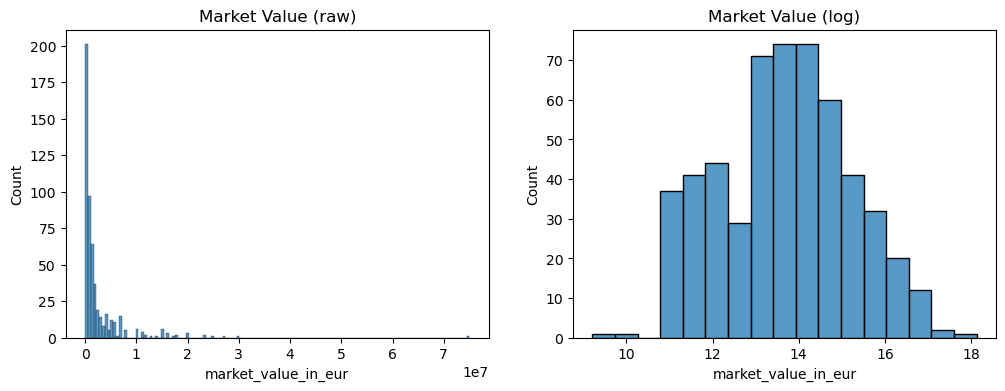

In [48]:
fig, ax = plt.subplots(1, 2 , figsize=(12,4))
sns.histplot(df["market_value_in_eur"], ax =ax[0])
ax[0].set_title("Market Value (raw)")

sns.histplot(np.log1p(df["market_value_in_eur"]), ax=ax[1])
ax[1].set_title("Market Value (log)") 
plt.show()

not: ham hali sağa çarpık, birkaç yıldız modeli domine ediyor (mse). log → dengeli dağılım, baseline R² -0.13 → 0.11 

In [49]:
num_cols=["market_value_in_eur","age","height_in_cm","games","minutes","goals","assists","yellow_cards","international_caps","contract_missing"]

In [50]:
corr = df[num_cols].corr()

In [51]:
plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

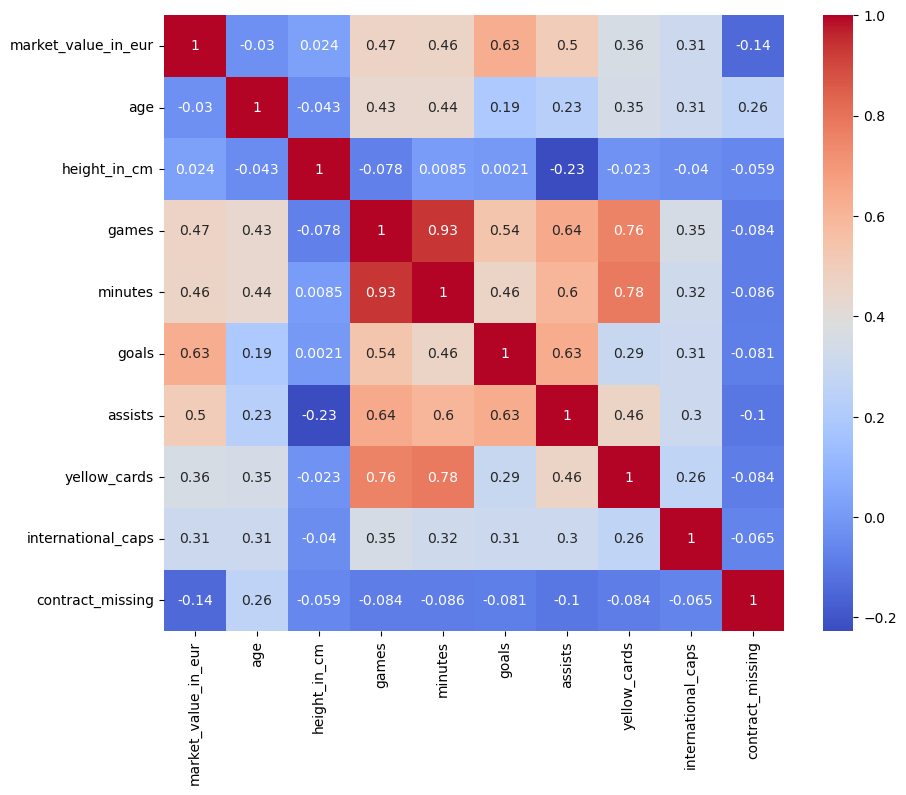

In [52]:
sns.heatmap(data = corr, annot=True, cmap="coolwarm")
plt.show()

not: target ile en güçlü ilişki goals (0.63). games-minutes 0.93 → multicollinearity, Ridge gerekçesi. age ~0 ama ilişki doğrusal değil (ters U) → grafik 4

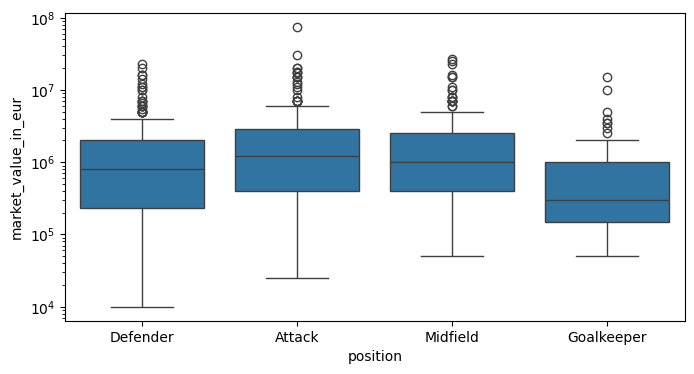

In [53]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x="position", y="market_value_in_eur")
plt.yscale("log")
plt.show()

 medyan en yüksek attack (1.2M), en düşük goalkeeper (300K). attack-midfield yakın. goals korelasyonunun bir kısmı pozisyon etkisi olabilir, ayırmak için çoklu regresyon

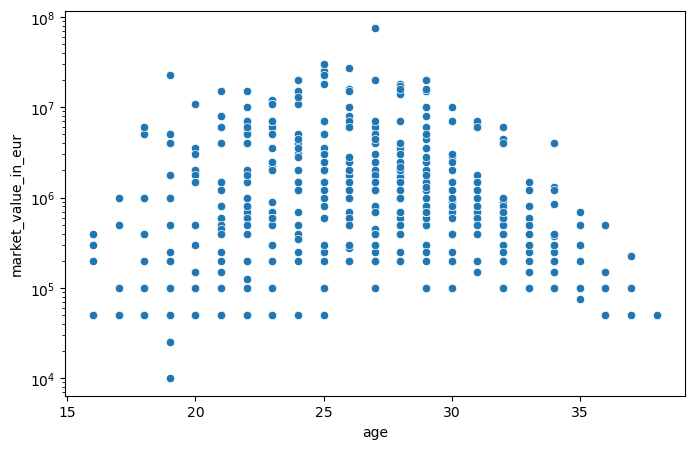

In [54]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="age",y="market_value_in_eur")
plt.yscale("log")
plt.show()

 ters U. değer 21 yaş altında düşük, 25-29 arası zirve, 30'dan sonra düşüyor. ilişki doğrusal değil → corr ~0 çıktı. modelde age² eklenecek

In [55]:
drop_cols = ["player_id","last_name","name","last_season","current_club_domestic_competition_id","current_club_id","contract_expiration_date","country_of_citizenship","sub_position","date_of_birth"]

In [56]:
y = df["market_value_in_eur"]
X = df.drop(columns=drop_cols + ["market_value_in_eur"])

In [57]:
X.columns

Index(['position', 'foot', 'height_in_cm', 'international_caps',
       'international_goals', 'current_club_name', 'contract_missing', 'games',
       'minutes', 'goals', 'assists', 'yellow_cards', 'age'],
      dtype='object')

In [58]:
X.shape

(540, 13)

In [59]:
cat_cols = ["position","foot","current_club_name"]

In [60]:
X = pd.get_dummies(X, columns=cat_cols , drop_first = True)

In [61]:
print(X.shape)
print(X.dtypes.value_counts())

(540, 32)
bool       22
float64     8
int64       1
int32       1
Name: count, dtype: int64


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [63]:
X.isnull().sum()[X.isnull().sum() > 0]

international_caps     99
international_goals    99
dtype: int64

In [64]:
X[["international_caps","international_goals"]] = X[["international_caps","international_goals"]].fillna(0)
X.isnull().sum().sum()

np.int64(0)

In [65]:
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [66]:
model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

In [67]:
r2_raw  = r2_score(y_test, y_pred)
mae_raw = mean_absolute_error(y_test, y_pred)
print("R2 :", r2_raw)
print("MAE:", mae_raw)

R2 : -0.13409040520279625
MAE: 1850035.9316740497


### Baseline sonuç
- LinearRegression: R² = -0.13, MAE ≈ 1.85M €
- Hedef değişken çok çarpık; birkaç yüksek değerli oyuncu modeli bozuyor olabilir. Sonraki adım: log dönüşümü.

In [68]:
y_log = np.log1p(y)

In [69]:
X_train,X_test,y_train_log,y_test_log = train_test_split(X, y_log, test_size = 0.2, random_state = 42)

In [70]:
model_log = LinearRegression()
model_log.fit(X_train,y_train_log)
y_pred_log = model_log.predict(X_test)

In [71]:
y_pred_eur = np.expm1(y_pred_log)

In [72]:
r2_log  = r2_score(y_test, y_pred_eur)
mae_log = mean_absolute_error(y_test, y_pred_eur)
print("R2 :", r2_log)
print("MAE:", mae_log)

R2 : 0.1099746154305592
MAE: 1158454.3070876093


In [73]:
results = pd.DataFrame({
    "Model": ["LinearRegression (ham hedef)", "LinearRegression (log hedef)"],
    "R2":  [r2_raw, r2_log],
    "MAE": [mae_raw, mae_log],
})
results

,Model,R2,MAE
0,LinearRegression (ham hedef),-0.134090,1.850036e+06
1,LinearRegression (log hedef),0.109975,1.158454e+06


### Sonuç
- Hedefe log dönüşümü uygulamak R²'yi -0.13 → 0.11'e çıkardı, MAE'yi ~%37 düşürdü (1.85M € → 1.16M €).
- Model hâlâ zayıf: veri az (540 oyuncu), cross-validation yok, sadece doğrusal model denendi.